# Keras VAD — annotated speech activity dataset
Train a small CNN–BiLSTM voice activity detector from WAV files and matching Praat TextGrid annotations, then compare with Silero VAD on held-out files. **Set `DATA_DIR` and inspect annotation labels before training.**

In [2]:
# Install once if needed:
# %pip install tensorflow librosa praatio scikit-learn matplotlib torch soundfile
import random
from pathlib import Path
from signal import valid_signals

import numpy as np
import librosa
import matplotlib.pyplot as plt
import tensorflow as tf
from praatio import textgrid
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
DATA_DIR = Path('/Users/nicoorth/Desktop/Schule/SemM1/SEP1/Notebooks/experiment/Software/data')  # Contains Audio/ and Annotation/
SR, HOP, N_FFT, N_MELS = 16000, 160, 400, 40  # 10 ms hop, 25 ms window
CHUNK_FRAMES = 200  # 2 seconds per training example
BATCH_SIZE = 16

In [3]:
print(tf.config.list_physical_devices("GPU"))

[]


In [4]:
# Pair files using their identical relative paths (apart from the extension).
audio_root = DATA_DIR / "audio"
annotation_root = DATA_DIR / "annotation"
pairs = []
for wav in sorted(audio_root.rglob("*.wav")):
    relative = wav.relative_to(audio_root)
    annotation = annotation_root / relative.with_suffix(".TextGrid")
    if annotation.exists():
        pairs.append((wav, annotation))
print(f"Matched WAV/TextGrid pairs: {len(pairs)}")
if not pairs:
    raise FileNotFoundError("No matching WAV/TextGrid files. Check DATA_DIR and extensions.")

Matched WAV/TextGrid pairs: 719


In [5]:
# Inspect the tiers and labels; adjust SILENCE_LABELS / SPEECH_LABELS below if needed.
tg = textgrid.openTextgrid(str(pairs[0][1]), includeEmptyIntervals=True)
for tier_name in tg.tierNames:
    tier = tg.getTier(tier_name)
    print(tier_name, [(round(e.start, 2), round(e.end, 2), e.label) for e in tier.entries[:12]])

silences [(0.0, 3.3, '0'), (3.3, 3.98, '1'), (3.98, 4.12, '0'), (4.12, 5.4, '1'), (5.4, 5.5, '0'), (5.5, 5.74, '1'), (5.74, 7.3, '0')]


**Label convention:** The selected interval tier must mark speech versus non-speech. Empty labels and common silence markers are treated as non-speech; other labels are treated as speech by default. If your TextGrids contain phoneme tiers, choose the appropriate speech-activity tier. Check the printed labels before continuing.

In [6]:
# Choose the correct interval tier after inspecting the output above.
TIER_NAME = None  # None = first interval tier; set e.g. "speech" if needed
SILENCE_LABELS = {"", "sil", "sp", "spn", "pau", "silence", "non-speech", "nonspeech", "noise", "0"}
SPEECH_LABELS = None  # Optional: e.g. {"speech", "1"}; None = any label not in SILENCE_LABELS

def speech_intervals(annotation_path):
    grid = textgrid.openTextgrid(str(annotation_path), includeEmptyIntervals=True)
    name = TIER_NAME or grid.tierNames[0]
    tier = grid.getTier(name)
    if not hasattr(tier, "entries"):
        raise ValueError(f"Tier {name} has no intervals")
    intervals = []
    for entry in tier.entries:
        label = entry.label.strip().lower()
        speech = label in SPEECH_LABELS if SPEECH_LABELS is not None else label not in SILENCE_LABELS
        if speech:
            intervals.append((float(entry.start), float(entry.end)))
    return intervals

def features_and_labels(wav_path, annotation_path):
    y, _ = librosa.load(wav_path, sr=SR, mono=True)
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP,
                                         n_mels=N_MELS, center=False)
    x = librosa.power_to_db(mel + 1e-10).T.astype("float32")
    # Normalize per recording; training and inference use the same transform.
    x = (x - x.mean(axis=0, keepdims=True)) / (x.std(axis=0, keepdims=True) + 1e-5)
    times = (np.arange(len(x)) * HOP + N_FFT / 2) / SR
    labels = np.zeros(len(x), dtype="float32")
    for start, end in speech_intervals(annotation_path):
        labels[(times >= start) & (times < end)] = 1
    return x, labels

print("Speech intervals in first file:", speech_intervals(pairs[0][1])[:10])

Speech intervals in first file: [(3.3, 3.9799999999999995), (4.124, 5.396), (5.5, 5.739999999999999)]


In [7]:
# Split by recording BEFORE chunking to avoid test-set leakage.
train_pairs, test_pairs = train_test_split(pairs, test_size=0.2, random_state=SEED)
train_pairs, val_pairs = train_test_split(train_pairs, test_size=0.2, random_state=SEED)
print(len(train_pairs), len(val_pairs), len(test_pairs))

def chunks(pairs_list):
    for wav, annotation in pairs_list:
        x, labels = features_and_labels(wav, annotation)
        for start in range(0, len(x), CHUNK_FRAMES):
            end = start + CHUNK_FRAMES
            if end > len(x):
                break  # Only full chunks for training
            yield x[start:end], labels[start:end, None]

def dataset(pairs_list, shuffle=False):
    ds = tf.data.Dataset.from_generator(
        lambda: chunks(pairs_list),
        output_signature=(tf.TensorSpec((CHUNK_FRAMES, N_MELS), tf.float32),
                          tf.TensorSpec((CHUNK_FRAMES, 1), tf.float32)))
    if shuffle:
        ds = ds.shuffle(64, seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = dataset(train_pairs, True), dataset(val_pairs)

460 115 144


In [8]:
# calculating training and validation steps
train_steps, val_steps = 49, 13
# train_steps = sum(1 for _ in train_ds)  # 49
# val_steps = sum(1 for _ in val_ds)      # 13

print("Training batches:", train_steps)
print("Validation batches:", val_steps)

Training batches: 49
Validation batches: 13


In [ ]:
# Compact frame-wise CNN–BiLSTM model.
model = tf.keras.Sequential([
    tf.keras.layers.Input((None, N_MELS)),
    tf.keras.layers.Conv1D(64, 5, padding="same", activation="relu"),
    tf.keras.layers.Conv1D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy",
              metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy")])
history = model.fit(
                train_ds,
                validation_data=val_ds,
                steps_per_epoch=train_steps,
                validation_steps=val_steps,
                epochs=30,
                shuffle=False,
                callbacks=[
                    tf.keras.callbacks.EarlyStopping(
                        monitor="val_loss",
                        patience=7,
                        restore_best_weights=True
                    ),
                    tf.keras.callbacks.ReduceLROnPlateau(
                        monitor="val_loss",
                        factor=0.5,
                        patience=2,
                        min_lr=1e-6
                    )
                ]
            )
model.save("keras_vad.keras")

Epoch 1/30


In [54]:
# Predict all frames, including a shorter final chunk.
def keras_probabilities(wav_path):
    x, _ = features_and_labels(wav_path, annotation_root / wav_path.relative_to(audio_root).with_suffix(".TextGrid"))
    outputs = []
    for start in range(0, len(x), CHUNK_FRAMES):
        outputs.append(model.predict(x[start:start + CHUNK_FRAMES][None], verbose=0)[0, :, 0])
    return np.concatenate(outputs) if outputs else np.array([])

def mask_to_intervals(mask, frame_seconds=HOP / SR):
    edges = np.diff(np.r_[0, mask.astype(int), 0])
    starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0]
    return [(round(s * frame_seconds, 3), round(e * frame_seconds, 3)) for s, e in zip(starts, ends)]

THRESHOLD = 0.5
wav, annotation = test_pairs[0]
probs = keras_probabilities(wav)
print("Keras speech regions (seconds):", mask_to_intervals(probs >= THRESHOLD)[:20])

Keras speech regions (seconds): [(np.float64(0.21), np.float64(2.0)), (np.float64(2.01), np.float64(2.79))]


In [55]:
# Silero VAD: first run downloads the model via torch.hub (internet required).
import torch
silero_model, silero_utils = torch.hub.load(
    repo_or_dir="snakers4/silero-vad", model="silero_vad", trust_repo=True)
get_speech_timestamps = silero_utils[0]

def silero_intervals(wav_path):
    y, _ = librosa.load(wav_path, sr=SR, mono=True)
    regions = get_speech_timestamps(torch.from_numpy(y), silero_model,
                                    sampling_rate=SR, return_seconds=True)
    return [(r["start"], r["end"]) for r in regions]

def intervals_to_mask(intervals, count):
    times = (np.arange(count) * HOP + N_FFT / 2) / SR
    mask = np.zeros(count, dtype=bool)
    for start, end in intervals:
        mask |= (times >= start) & (times < end)
    return mask

Using cache found in /home/sde_sep1_ai1/.cache/torch/hub/snakers4_silero-vad_master


In [56]:
# Compare both methods on exactly the same held-out recordings and annotated frames.
true_all, keras_all, silero_all = [], [], []
for wav, annotation in test_pairs:
    _, truth = features_and_labels(wav, annotation)
    keras_mask = keras_probabilities(wav) >= THRESHOLD
    silero_mask = intervals_to_mask(silero_intervals(wav), len(truth))
    true_all.extend(truth.astype(int))
    keras_all.extend(keras_mask.astype(int))
    silero_all.extend(silero_mask.astype(int))

for name, prediction in [("Keras", keras_all), ("Silero", silero_all)]:
    precision, recall, f1, _ = precision_recall_fscore_support(
        true_all, prediction, average="binary", zero_division=0)
    print(f"{name:7s} precision={precision:.3f} recall={recall:.3f} F1={f1:.3f}")

Keras   precision=0.922 recall=0.935 F1=0.928
Silero  precision=0.739 recall=0.995 F1=0.848


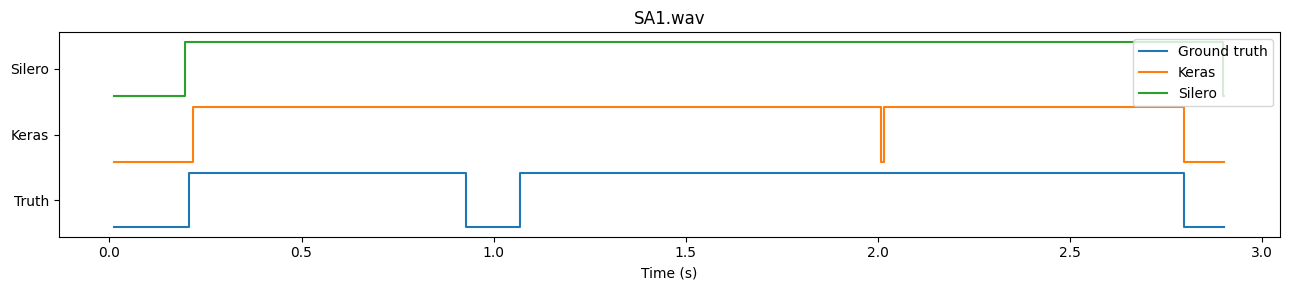

Keras timestamps: [(np.float64(0.21), np.float64(2.0)), (np.float64(2.01), np.float64(2.79))]
Silero timestamps: [(0.2, 2.9)]


In [57]:
# Visual check: ground truth versus both models on one test recording.
wav, annotation = test_pairs[0]
_, truth = features_and_labels(wav, annotation)
keras_mask = keras_probabilities(wav) >= THRESHOLD
silero_mask = intervals_to_mask(silero_intervals(wav), len(truth))
t = (np.arange(len(truth)) * HOP + N_FFT / 2) / SR
plt.figure(figsize=(13, 3))
plt.step(t, truth, where="mid", label="Ground truth")
plt.step(t, keras_mask.astype(int) + 1.2, where="mid", label="Keras")
plt.step(t, silero_mask.astype(int) + 2.4, where="mid", label="Silero")
plt.yticks([0.5, 1.7, 2.9], ["Truth", "Keras", "Silero"])
plt.xlabel("Time (s)")
plt.title(wav.name)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()
print("Keras timestamps:", mask_to_intervals(keras_mask))
print("Silero timestamps:", silero_intervals(wav))
